# IAU Projekt
## Fáza 4

**Predmet:** Inteligentná analýza údajov (IAU)<br>
**Akademický rok / semester:** 2026/2027<br>
**Cvičiaci:** Ing. Laura Krajčovičová<br>
**Dataset:** Ecommerce classify the objects based on their text description<br>
**Autori:** Adam Kavoň, Jakub Žúbor

**Podiel práce:**

- **4.1 EDA and data preprocessing:** Adam Kavoň 100 %, Jakub Žúbor 0 %
- **4.2. Modeling and evaluation:** Adam Kavoň 0 %, Jakub Žúbor 100 %

**Celkový podiel práce na fáze 4:** Adam Kavoň 50 %, Jakub Žúbor 50 %

## Riešenie

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

## A) 4.1 EDA and data preprocessing

Ako prvé si vypíšeme surové dáta, ako sú uložené, aby sme zistili s akým separátorom ich následne otvoriť. 

In [2]:
with open(f"data/ecommerceDataset.csv", "r", encoding="utf-8", errors="replace") as f:
        for i, line in enumerate(f):
            print(i, repr(line))
            if i >= 2:
                break

0 'Household,"Paper Plane Design Framed Wall Hanging Motivational Office Decor Art Prints (8.7 X 8.7 inch) - Set of 4 Painting made up in synthetic frame with uv textured print which gives multi effects and attracts towards it. This is an special series of paintings which makes your wall very beautiful and gives a royal touch. This painting is ready to hang, you would be proud to possess this unique painting that is a niche apart. We use only the most modern and efficient printing technology on our prints, with only the and inks and precision epson, roland and hp printers. This innovative hd printing technique results in durable and spectacular looking prints of the highest that last a lifetime. We print solely with top-notch 100% inks, to achieve brilliant and true colours. Due to their high level of uv resistance, our prints retain their beautiful colours for many years. Add colour and style to your living space with this digitally printed painting. Some are for pleasure and some for

Vo výpise vidíme, že záznam na indexe 0 neobsahuje názvy stĺpcov. Keďže vieme, že dataset obsahuje 2 stĺpce otvoríme súbor s príslušnými názvami.

In [3]:
ecommerce_data = pd.read_csv("data/ecommerceDataset.csv", sep=",", names=["category", "description"])
ecommerce_data

,category,description
0,Household,Paper Plane Design Framed Wall Hanging Motivat...
1,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x ..."
2,Household,SAF 'UV Textured Modern Art Print Framed' Pain...
3,Household,"SAF Flower Print Framed Painting (Synthetic, 1..."
4,Household,Incredible Gifts India Wooden Happy Birthday U...
...,...,...
50420,Electronics,Strontium MicroSD Class 10 8GB Memory Card (Bl...
50421,Electronics,CrossBeats Wave Waterproof Bluetooth Wireless ...
50422,Electronics,Karbonn Titanium Wind W4 (White) Karbonn Titan...
50423,Electronics,"Samsung Guru FM Plus (SM-B110E/D, Black) Colou..."


### Analýza dát

In [4]:
ecommerce_data.info()
ecommerce_data.shape

<class 'pandas.DataFrame'>
RangeIndex: 50425 entries, 0 to 50424
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   category     50425 non-null  str  
 1   description  50424 non-null  str  
dtypes: str(2)
memory usage: 788.0 KB


(50425, 2)

In [5]:
ecommerce_data["category"].unique()

<StringArray>
['Household', 'Books', 'Clothing & Accessories', 'Electronics']
Length: 4, dtype: str

Dataset obsahuje 50425 riadkov a 2 stĺpce. Vo výpise taktiež vidno 2 atribúty, ich dátový typ a počet nie Null záznamov. Oba atribúty sú dátového typu string. `Category` neobsahuje ani jeden Null záznam, no `description` obsahuje presne 1. Ide o zanedbateľné množstvo, a preto tento záznam môže byť odstránený.

Kategória obsahuje 4 rôzne kategórie: `Household`, `Books`, `Clothing & Accessories`, `Electronics`

### Vyváženosť kategórií

In [6]:
ecommerce_data["category"].value_counts()

category
Household                 19313
Books                     11820
Electronics               10621
Clothing & Accessories     8671
Name: count, dtype: int64

Distribúcia produktov v datasete je mierne nevyvážená. Najpočetnejšou kategóriou je `Household` (19 313 produktov), ktorá tvorí približne 38,3 % datasetu. Nasledujú `Books` (23,4 %), `Electronics` (21,1 %) a najmenej zastúpená kategória `Clothing & Accessories` (17,2 %).

### Duplicity

In [7]:
print("Duplicitné riadky:")
print(ecommerce_data.duplicated().sum())

print("Prázdne opisy:")
print((ecommerce_data["description"].fillna("").str.strip() == "").sum())

Duplicitné riadky:
22622
Prázdne opisy:
1


Dataset obsahuje 1 záznam , kedy v description je prázdny text (""). Znova ide o zanedbateľné množstvo, a preto tento záznam bude odstránený.

Dataset obsahuje 22622 duplicitných riadkov, čo tvorí približne 44,9 % všetkých záznamov. Ak by sme ponechali tieto záznamy pri trénovaní modelu, jeho úspešnosť by bola umelo navýšená.

### Dĺžky textových opisov

In [8]:
ecommerce_data["word_count"] = ecommerce_data["description"].fillna("").apply(
    lambda x: len(str(x).split())
)

ecommerce_data["char_count"] = ecommerce_data["description"].fillna("").apply(
    lambda x: len(str(x))
)

print(ecommerce_data[["word_count", "char_count"]].describe())

         word_count    char_count
count  50425.000000  50425.000000
mean     114.182033    714.098185
std      157.806226    973.370093
min        0.000000      0.000000
25%       34.000000    219.000000
50%       78.000000    487.000000
75%      152.000000    954.000000
max     8181.000000  50403.000000


Priemerný počet slov je **114,18** (`std = 157,81`), zatiaľ čo medián je len **78** slov (pri znakoch je priemer **714,10** a medián **487**). Niekoľko extrémne dlhých popisov (maximum **8 181** slov / **50 403** znakov) ťahá priemer výrazne nahor.

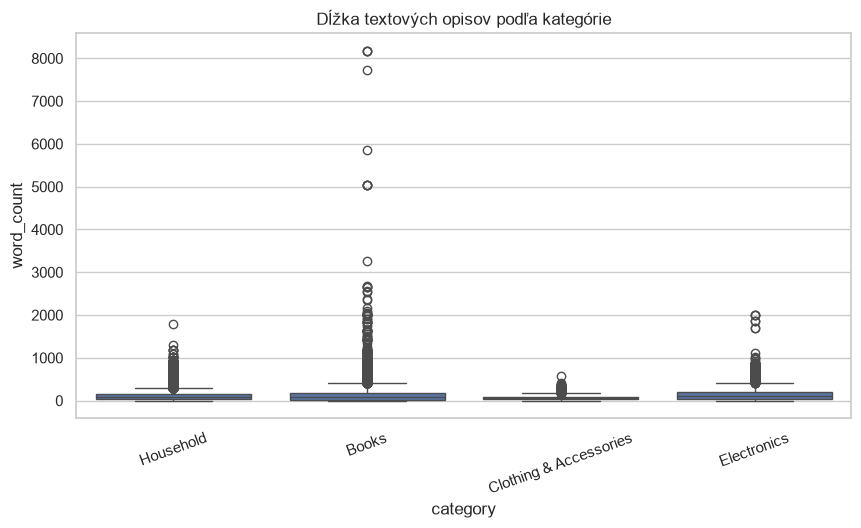

In [9]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=ecommerce_data,
    x="category",
    y="word_count"
)

plt.title("Dĺžka textových opisov podľa kategórie")
plt.xticks(rotation=20)
plt.show()

Veľké množstvo odľahlých hodnôt, najmä v kategórii **Books** (až nad 8 000 slov) a tiež v **Electronics** a **Household**.

## Čistenie dát

### Prázdne a duplicitné hodnoty

Zistili sme 1 prázdnu hodnotu a príliš veľa duplicitných hodnôt. Tieto záznamy odstránime.

In [10]:
n_before = len(ecommerce_data)

# 1. Prázdne alebo chýbajúce opisy
mask_empty = ecommerce_data["description"].fillna("").str.strip() == ""
data_clean = ecommerce_data.loc[~mask_empty, ["category", "description"]].copy()

# 2. Presné duplicity
data_clean = data_clean.drop_duplicates()

data_clean = data_clean.reset_index(drop=True)
print(f"Pred čistením: {n_before}, po čistení: {len(data_clean)} "
      f"(odstránených {n_before - len(data_clean)}, {(n_before - len(data_clean)) / n_before:.1%})")

Pred čistením: 50425, po čistení: 27802 (odstránených 22623, 44.9%)


In [11]:
conf = data_clean.groupby("description")["category"].nunique()
print("Opisy s viacerými kategóriami:", (conf > 1).sum())

Opisy s viacerými kategóriami: 0


### Outliery
Taktiež z grafu vidno outliere pri kategórií `Books`. Hranicu 3000 znakov sme zvolili podľa boxplotu, kde sa väčšina hodnôt nachádza pod touto úrovňou.

In [12]:
data_clean["char_count"] = data_clean["description"].str.len()
long_mask = data_clean["char_count"] > 3000
print("Záznamy s viac ako 3000 znakmi:", long_mask.sum(),
      f"({long_mask.mean():.1%} dát)")

Záznamy s viac ako 3000 znakmi: 443 (1.6% dát)


Tieto outliere tvoria len 1.6% dát a skúsime ich nechať v dátach bez ich odstránenia.

### Nie-ASCII, HTML a URL značky

In [13]:
d = data_clean["description"]
noise = pd.Series({
    "obsahuje číslice": d.str.contains(r"\d").mean(),
    "obsahuje nie-ASCII znaky": d.apply(lambda s: not s.isascii()).mean(),
    "obsahuje HTML značky": d.str.contains(r"<[^>]+>").mean(),
    "obsahuje URL": d.str.contains(r"http|www\.", case=False).mean(),
})
display((noise * 100).round(1).rename("podiel opisov (%)").to_frame())

,podiel opisov (%)
obsahuje číslice,77.4
obsahuje nie-ASCII znaky,19.9
obsahuje HTML značky,0.1
obsahuje URL,0.7


Číslice v popisoch sú v poriadku, môže ísť o rozmery a podobne. Bližšie sa pozrieme na nie-ASCII znaky.

In [14]:
from collections import Counter

chars = Counter(ch for s in data_clean["description"] for ch in s if ord(ch) > 127)
display(pd.DataFrame(chars.most_common(15), columns=["znak", "počet"]))

,znak,počet
0,,9455
1,’,6055
2,”,2979
3,“,2808
4,—,2577
5,–,1358
6,•,897
7,ा,745
8,…,691
9,‘,670


Z tabuľky vidno, že niektoré znaky sú neznáme. S pomocou ChatGPT sme zistili, že patria do písma Devanagari, ktoré sa používa v hindčine

In [15]:
has_hindi = data_clean["description"].str.contains(r"[\u0900-\u097F]")
print("Opisy s hindčinou:", has_hindi.sum(), f"({has_hindi.mean():.1%})")
display(data_clean.loc[has_hindi, "category"].value_counts().to_frame("počet"))

Opisy s hindčinou: 18 (0.1%)


,počet
category,
Books,15
Electronics,2
Household,1


Opisov v tomto jazyku je len 18 záznamov (0.1 %). Rozhodli sme sa, že ich odstránime kvôli jazykovej nekonzistentnosti, keďže všetok ostatný text je po anglicky.

In [16]:
data_clean = data_clean[~has_hindi].reset_index(drop=True)

HTML a URL značky sa nachádzajú len v malom prípade záznamov. Nechceme odstrániť celé záznamy, ale z pôvodného textu len značky a adresy.

In [17]:
import re
import unicodedata
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

CHAR_MAP = str.maketrans({
    "\xa0": " ", "’": "'", "‘": "'", "“": '"', "”": '"',
    "–": " ", "—": " ", "―": " ", "•": " ", "…": " ",
})

def normalize_text(text):
    text = text.translate(CHAR_MAP)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", text).strip()
    
# Funkcia na čistenie textu
def clean_text(text):
    text = normalize_text(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)                      # HTML
    text = re.sub(r"(?:https?://|www\.)\S+", " ", text)       # URL
    text = re.sub(r"\b\d+(?:[.,]\d+)*\b", " num ", text)      # samostatné čísla -> token "num"
    text = text.replace("'", "")                              # men's -> mens
    text = re.sub(r"[^a-z0-9\s]", " ", text)                  # interpunkcia
    tokens = [t for t in text.split()
              if len(t) > 1 and t not in ENGLISH_STOP_WORDS]  # stop slová a 1-písmenové tokeny
    return " ".join(tokens)

data_clean["text_clean"] = data_clean["description"].apply(clean_text)

# Ukážka pred a po
example = data_clean.iloc[10]
print("PRED :", example["description"][:300])
print("\nPO   :", example["text_clean"][:300])

PRED : Painting Mantra 'Vintage Car' Art Printing Set (Synthetic Wood, 60 cm x 50 cm x 2 cm, Brown, Set of 4) Size:60 cm x 50 cm x 2 cm   From the house of art street, we bring this exclusive framed poster to satiate the taste of decor freaks and vintage cars lovers. The filling station-vintage car brown f

PO   : painting mantra vintage car art printing set synthetic wood num cm num cm num cm brown set num size num cm num cm num cm house art street bring exclusive framed poster satiate taste decor freaks vintage cars lovers filling station vintage car brown framed poster high resolution vintage poster comes 


Funkcia `clean_text` najprv zjednotí typografické znaky (úvodzovky, pomlčky) a odstráni nie-ASCII znaky. Prevedie veľké písmená na malé, obsah textu sa nezmení. Samostatné čísla nahradí tokenom `num` (rozmery a čísla samotné nenesú informáciu o kategórii, ale ich prítomnosť môže byť užitočná). Odstráni HTML značky a URL, odstráni apostrofy a interpunkciu. Nakoniec odstráni stop slová a jednopísmenové tokeny.

### Duplicity a prázdne texty po čistení textu

Čistenie textu (odstránenie interpunkcie, čísel a stop slov) môže z rôznych opisov vyrobiť rovnaké texty alebo opis úplne vyprázdniť.

In [18]:
# prázdne texty po čistení
print("Prázdne po čistení:", (data_clean["text_clean"].str.strip() == "").sum())

# nové duplicity
print("Duplicity na odstránenie:", data_clean.duplicated(subset="text_clean").sum())

# rovnaký čistý text, rôzne kategórie
conf = data_clean.groupby("text_clean")["category"].nunique()
conflict_texts = conf[conf > 1].index
print("Texty s viacerými kategóriami:", len(conflict_texts))

display(data_clean.loc[data_clean["text_clean"].isin(conflict_texts),
                       ["category", "description", "text_clean"]])

Prázdne po čistení: 1
Duplicity na odstránenie: 316
Texty s viacerými kategóriami: 1


,category,description,text_clean
11478,Books,HP AIO 20-C102IL 19.5-Inch Screen All-In-One D...,hp aio num c102il num inch screen desktop cele...
23523,Electronics,HP AIO 20-C102IL 19.5-Inch Screen All-In-One D...,hp aio num c102il num inch screen desktop cele...


In [19]:
n_before = len(data_clean)

# 1. prázdne texty
data_clean = data_clean[data_clean["text_clean"].str.strip() != ""]

# 2. konfliktné texty
data_clean = data_clean[~data_clean["text_clean"].isin(conflict_texts)]

# 3. duplicity
data_clean = data_clean.drop_duplicates(subset="text_clean").reset_index(drop=True)

print(f"Pred: {n_before}, po: {len(data_clean)} "
      f"(odstránených {n_before - len(data_clean)}, {(n_before - len(data_clean)) / n_before:.1%})")

Pred: 27784, po: 27466 (odstránených 318, 1.1%)


Po vyčistení textu sme našli 1 prázdny text, 1 text s konfliktnou kategóriou a 316 nových duplicít. Konfliktný text sme odstránili celý, pretože nevieme určiť správnu kategóriu. Z duplicít sme ponechali vždy jeden záznam.

## Analýza po čistení

In [20]:
from sklearn.feature_extraction.text import CountVectorizer

top_words = {}
for cat, grp in data_clean.groupby("category"):
    cv = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
    X = cv.fit_transform(grp["text_clean"])
    counts = np.asarray(X.sum(axis=0)).ravel()
    words = np.array(cv.get_feature_names_out())
    top_words[cat] = words[counts.argsort()[::-1][:12]]
display(pd.DataFrame(top_words))

,Books,Clothing & Accessories,Electronics,Household
0,num,num,num,num
1,book,cotton,usb,set
2,author,wear,camera,home
3,new,size,black,use
4,books,womens,high,easy
5,review,fit,power,steel
6,world,fabric,cable,size
7,life,look,bluetooth,quality
8,university,women,audio,color
9,times,girls,wireless,product


Každá kategória má výrazne odlišnú slovnú zásobu, viď tabuľka vyššie. Číslice sme nahradili reťazcom num, preto v každej kategórii vyšiel tento reťazec, ako najviac používaný. Z toho dôvodu ho nemožno považovať za významné rozlišovacie slovo.

In [21]:
data_clean["category"].value_counts()

category
Household                 10481
Books                      6128
Clothing & Accessories     5588
Electronics                5269
Name: count, dtype: int64

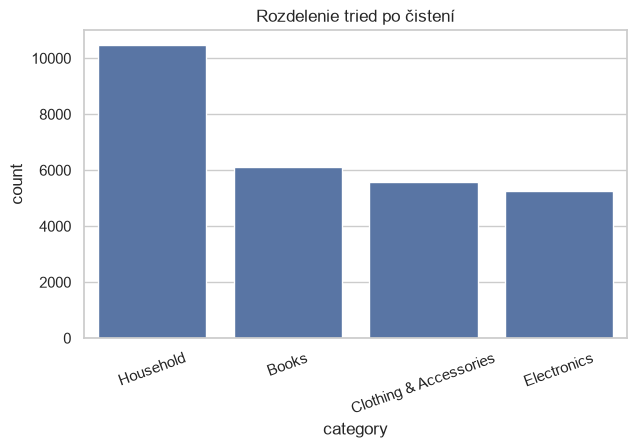

In [22]:
plt.figure(figsize=(7, 4))
sns.countplot(data=data_clean, x="category",
              order=data_clean["category"].value_counts().index)
plt.title("Rozdelenie tried po čistení")
plt.xticks(rotation=20)
plt.show()

Po čistení zostáva distribúcia kategórií mierne nevyvážená, no rozdiely medzi menšími triedami sa vyrovnali (viď graf). Najväčšie zastúpenie má stále kategória Household (10 481 záznamov, 38,2 %). Nasledujú Books (22,3 %), Clothing & Accessories (20,3 %) a najmenej zastúpená je Electronics (19,2 %). Celkové rozdelenie by nemalo spôsobovať extrémnu nerovnováhu tried pri ďalšom spracovaní.

## Rozdelenie na train a test

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(data_clean["category"])
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    data_clean["text_clean"], y, test_size=0.2, stratify=y, random_state=42)

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2)
X_train = tfidf.fit_transform(X_train_txt)   # fit len na train
X_test = tfidf.transform(X_test_txt)
print(X_train.shape, X_test.shape, dict(zip(le.classes_, le.transform(le.classes_))))

(21972, 20000) (5494, 20000) {'Books': np.int64(0), 'Clothing & Accessories': np.int64(1), 'Electronics': np.int64(2), 'Household': np.int64(3)}


Kategórie sme zakódovali na čísla (Books = 0, Clothing & Accessories = 1, Electronics = 2, Household = 3) a dáta sme stratifikovane rozdelili v pomere 80 : 20 na 21 972 trénovacích a 5 494 testovacích záznamov. Texty sme previedli na TF-IDF príznaky (slová aj dvojice slov, najviac 20 000 príznakov), pričom slovník sme naučili len na trénovacích dátach, aby do modelu neunikali informácie z testovacej množiny. Výsledkom sú matice s rozmermi (21972, 20000) a (5494, 20000), ktoré použijeme na modelovanie v 4.2.

In [24]:
train_dist = pd.Series(le.inverse_transform(y_train)).value_counts(normalize=True).round(3) * 100
test_dist = pd.Series(le.inverse_transform(y_test)).value_counts(normalize=True).round(3) * 100

display(pd.DataFrame({"train (%)": train_dist, "test (%)": test_dist}))

,train (%),test (%)
Household,38.2,38.2
Books,22.3,22.3
Clothing & Accessories,20.3,20.3
Electronics,19.2,19.2


Rozdelenie tried je v trénovacej aj testovacej množine rovnaké.

## 4.1 B) Zdôvodnenie výberu ML/DL metód pre 4.2

**Charakter úlohy:** ide o viactriednu (4 triedy) klasifikáciu textu v angličtine. Vstupom je voľný text produktového opisu, výstupom kategória produktu. Dataset má po čistení približne 27 tis. záznamov s mierne nevyváženými triedami (najväčšia Household ~38 %, najmenšia Electronics ~19 %).

**Zistenia z EDA, ktoré ovplyvnili výber:**
- Každá kategória má výrazne odlišnú slovnú zásobu. Trieda je preto do veľkej miery určená prítomnosťou kľúčových slov, čo je ideálne pre modely nad TF-IDF reprezentáciou.
- Texty sú dlhé (medián ~78 slov), takže bag-of-words príznaky nesú dostatok informácie.
- 27 tis. vzoriek je dostatočné množstvo na trénovanie klasických modelov.
- Nerovnováha tried je mierna, preto použijeme stratifikovaný split, `class_weight="balanced"` a metriku macro-F1 popri accuracy.

**Zvolené metódy:**

Použijeme tri klasické modely nad TF-IDF príznakmi. **Logistická regresia** je rýchly a dobre interpretovateľný baseline, ktorý na textových dátach s odlišnou slovnou zásobou tried zvyčajne funguje veľmi dobre. **Linear SVM** je pri riedkych vysokorozmerných TF-IDF príznakoch tradične silné a odolné voči overfittingu. **Multinomial Naive Bayes** je veľmi rýchly model založený na početnosti slov, ktorý slúži ako ďalší baseline na porovnanie. Zložitejšie neurónové siete nepoužijeme, pretože EDA ukázala, že trieda je do veľkej miery určená prítomnosťou kľúčových slov. Na takú úlohu stačia jednoduché modely, ktoré sa rýchlo trénujú a ľahko interpretujú.

**Hodnotenie:** accuracy, macro-F1, confusion matrix a klasifikačný report po triedach. Modely porovnáme podľa macro-F1 na testovacej množine a ako najlepší vyberieme ten s najvyššou hodnotou.

## Ukážka dát po vyčistení

In [25]:
data_clean

,category,description,char_count,text_clean
0,Household,Paper Plane Design Framed Wall Hanging Motivat...,1338,paper plane design framed wall hanging motivat...
1,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x ...",346,saf floral framed painting wood num inch num i...
2,Household,SAF 'UV Textured Modern Art Print Framed' Pain...,1316,saf uv textured modern art print framed painti...
3,Household,"SAF Flower Print Framed Painting (Synthetic, 1...",1091,saf flower print framed painting synthetic num...
4,Household,Incredible Gifts India Wooden Happy Birthday U...,989,incredible gifts india wooden happy birthday u...
...,...,...,...,...
27461,Electronics,Micromax Bharat 5 Plus Zero impact on visual d...,144,micromax bharat num plus zero impact visual di...
27462,Electronics,Microsoft Lumia 550 8GB 4G Black Microsoft lum...,1924,microsoft lumia num 8gb 4g black microsoft lum...
27463,Electronics,"Microsoft Lumia 535 (Black, 8GB) Colour:Black ...",3931,microsoft lumia num black 8gb colour black pro...
27464,Electronics,Karbonn Titanium Wind W4 (White) Karbonn Titan...,1653,karbonn titanium wind w4 white karbonn titaniu...
